# Лабиринт и программируемая мышка
Выполняйте ячейки сверху вниз. Координаты — `(x, y)`, начало в левом верхнем углу. SVG-изображение обновляется средствами Jupyter; стены, проходы и движение задаются кодом. GUI-виджетов нет.

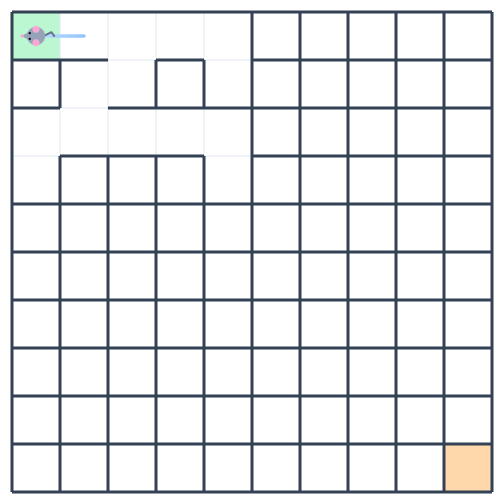

In [55]:
from IPython.display import display
from labyrinth import Maze, Mouse
from labyrinth_view import MazeView

def create_demo():
    """В Jupyter: maze, mouse, view = create_demo(); display(view)."""
    maze = Maze(10, 10, mode="closed")
    maze.open_path(
        [
            (0, 0),
            (1, 0),
            (2, 0),
            (2, 1),
            (1, 1),
            (1, 2),
            (2, 2),
            (3, 2),
            (4, 2),
            (4, 3),
        ]
    )
    maze.open_path([(2, 0), (3, 0), (4, 0), (4, 1)])  # Тупик.
    maze.open_path([(1, 2), (0, 2), (0, 3)])  # Ещё один тупик.
    mouse = Mouse(maze, trail_ttl=1)
    return maze, mouse, MazeView(maze, mouse)

maze, mouse, view = create_demo()
view  # Последняя строка ячейки — стандартный вывод Jupyter.

In [41]:
from random import randint
from time import sleep

In [56]:
methods = (mouse.down, mouse.right, mouse.left, mouse.up)
for i in range(100):
    method = methods[randint(0, 3)]
    method()
    sleep(0.05)

In [38]:
mouse.down()

1

In [3]:
# Мгновенные команды: абсолютное направление и движение вперёд.
mouse.right(2)
mouse.down()
print('Клетка:', mouse.position, 'Выход:', mouse.at_exit)

Клетка: (2, 1) Выход: False


In [ ]:
# Анимированное прохождение; await в Jupyter доступен прямо в ячейке.
mouse.reset()
await mouse.walk(['right', 'right', 'down', 'left', 'down',
                  'right', 'right', 'right', 'down'], delay=0.25)
print('Выход найден:', mouse.at_exit)

## Свой лабиринт: расстановка стен
По умолчанию все связи открыты, а противоположные края соединены. Стены задаются удалением направленных ссылок между объектами клеток.

In [ ]:
my_maze = Maze(6, 4, entrance=(0, 0), exit=(5, 3))
for y in range(my_maze.height - 1):
    my_maze.add_wall((1, y), 'right')  # Стена справа от клетки.
my_mouse = Mouse(my_maze)
my_view = MazeView(my_maze, my_mouse)
display(my_view)

In [ ]:
# Возвращается число пройденных клеток: перед стеной мышка остановится.
my_mouse.right(5)

In [ ]:
# Изменения сразу отражаются в ранее показанном SVG.
my_maze.remove_wall((1, 0), 'right')
my_maze.entrance = (0, 1)
my_maze.exit = (5, 0)
my_mouse.reset()
my_view.show_trail = False
my_view.show_grid = False
print('Корень:', my_maze.root, 'Слева от корня:', my_maze.root.left)
print('Соседи:', my_maze.neighbors(my_mouse.position))
print('Проходы:', my_maze.links)